# Perceptron from Scratch — Batch vs. Sequential

NumPy implementations of the batch and sequential perceptron learning rules on a linearly separable dataset, plus a learning-rate sweep (0.001 → 100) comparing convergence speed and test accuracy.

# 1.1

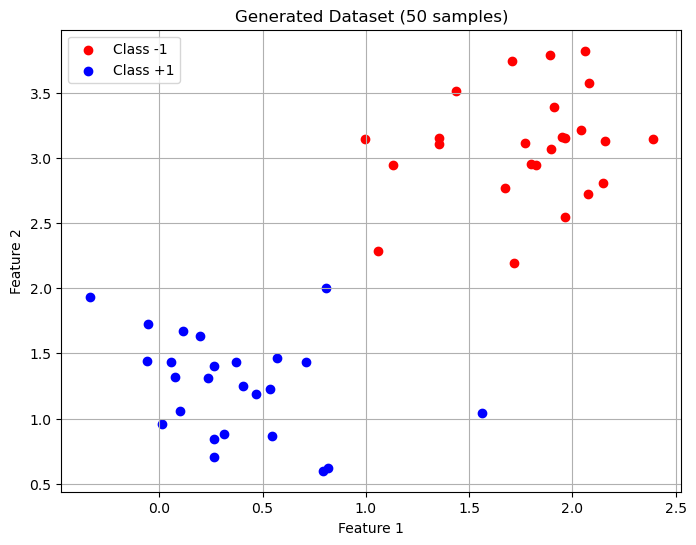

In [1]:
from sklearn import datasets
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

n = 50
X, y = datasets.make_blobs(n_samples=n, centers=2, n_features=2, center_box=(0, 3), cluster_std=0.4, random_state=1247)

y = y*2-1
y = y.reshape(n,1)
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.4,random_state=420)

plt.figure(figsize=(8, 6))
plt.scatter(X[y.ravel() == -1, 0], X[y.ravel() == -1, 1], c='red', label='Class -1')
plt.scatter(X[y.ravel() == 1, 0], X[y.ravel() == 1, 1], c='blue', label='Class +1')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Generated Dataset (50 samples)')
plt.legend()
plt.grid(True)
plt.show()

# 1.2

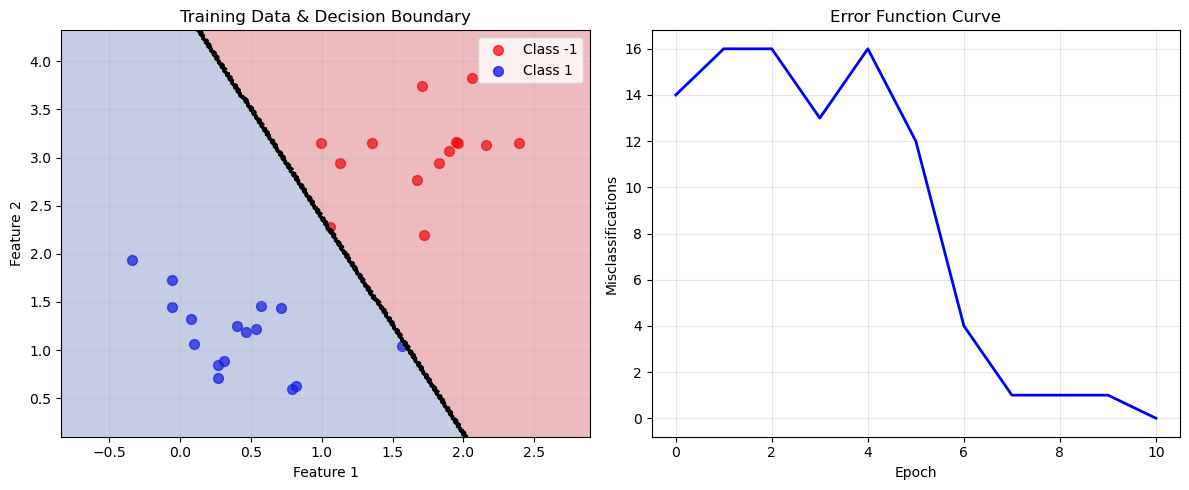

Final weights: [ 3.89671415 -1.88990773 -0.84297434]
Training epochs: 11


In [2]:
class BatchPerceptron:
    def __init__(self, lr=0.1, epochs=1000, random_state=42):
        self.lr = lr  # Learning rate
        self.epochs = epochs  # Maximum training iterations
        self.W = None  # Weight vector [w0, w1, w2] where w0 is bias
        self.errors = []  # Error history
        self.random_state = random_state
        np.random.seed(self.random_state)
    
    def fit(self, X, y):
        self.W = np.random.randn(X.shape[1] + 1)
        self.errors = []
        
        for epoch in range(self.epochs):
            # Make predictions: w0 + X * [w1, w2]
            y_pred = np.sign(self.W[0] + X @ self.W[1:])
            y_pred[y_pred == 0] = -1
            # Count misclassified samples
            misclassified = (y_pred.flatten() != y.flatten())
            error_count = np.sum(misclassified)
            self.errors.append(error_count)
            
            # Stop if no errors
            if error_count == 0:
                break
            
            # Batch weight update
            w0_update = np.sum(y[misclassified])
            w1w2_update = np.sum(y[misclassified] * X[misclassified], axis=0)
            
            self.W[0] += self.lr * w0_update  # Update w0 (bias)
            self.W[1:] += self.lr * w1w2_update  # Update w1, w2
        
        return self
    
    def predict(self, X):
        y_pred_test = np.sign(self.W[0] + X @ self.W[1:])
        y_pred_test[y_pred_test == 0] = -1
        return y_pred_test

# Train batch perceptron model
batch_perceptron = BatchPerceptron(lr=0.1, epochs=100, random_state=42)
batch_perceptron.fit(X_train, Y_train)

# Create visualization plots
plt.figure(figsize=(12, 5))

# Plot 1: Training data and decision boundary
plt.subplot(1, 2, 1)
plt.scatter(X_train[Y_train.flatten() == -1, 0], X_train[Y_train.flatten() == -1, 1], 
            color='red', label='Class -1', s=50, alpha=0.7)
plt.scatter(X_train[Y_train.flatten() == 1, 0], X_train[Y_train.flatten() == 1, 1], 
            color='blue', label='Class 1', s=50, alpha=0.7)

# Create decision boundary
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

Z = batch_perceptron.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap='RdYlBu')
plt.contour(xx, yy, Z, colors='black', linewidths=2)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Training Data & Decision Boundary')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 2: Error curve
plt.subplot(1, 2, 2)
plt.plot(batch_perceptron.errors, 'b-', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Misclassifications')
plt.title('Error Function Curve')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print results
print(f"Final weights: {batch_perceptron.W}")
print(f"Training epochs: {len(batch_perceptron.errors)}")

# 1.3

In [3]:
batch_perceptron = BatchPerceptron(lr=0.1, epochs=100, random_state=42)
batch_perceptron.fit(X_train, Y_train)

Y_pred_batch = batch_perceptron.predict(X_test)
accuracy_batch = np.mean(Y_pred_batch == Y_test.flatten())
error_rate_batch = 1 - accuracy_batch

print(f"Batch Perceptron - Test Accuracy: {accuracy_batch:.4f}")
print(f"Batch Perceptron - Test Error Rate: {error_rate_batch:.4f}")

Batch Perceptron - Test Accuracy: 1.0000
Batch Perceptron - Test Error Rate: 0.0000


# 1.4

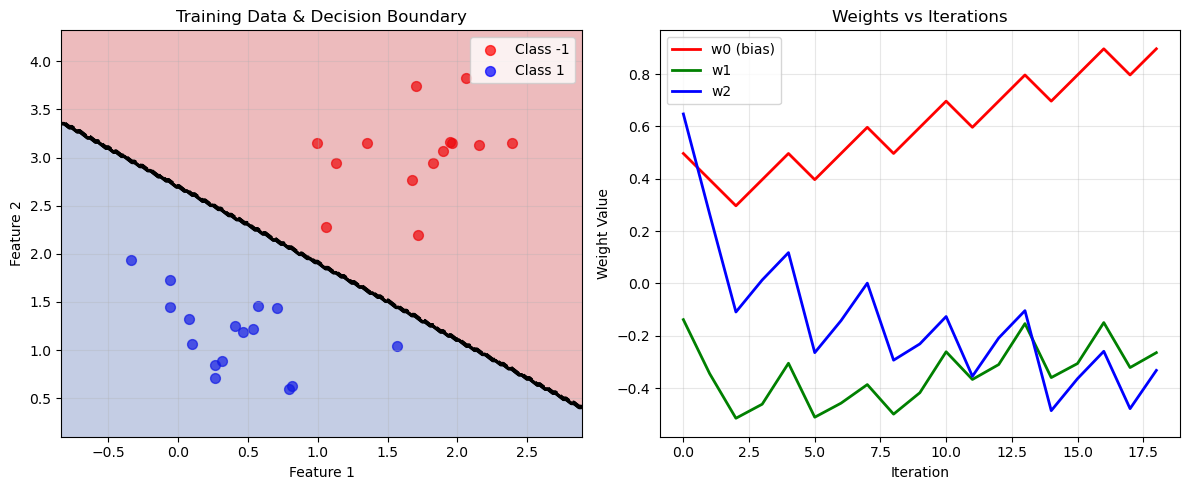

Final weights: [ 0.89671415 -0.26445722 -0.33220256]
Total iterations: 19


In [4]:
class SequentialPerceptron:
    def __init__(self, lr=0.1, epochs=1000, random_state=42):
        self.lr = lr  # Learning rate
        self.epochs = epochs  # Maximum training iterations
        self.W = None  # Weight vector [w0, w1, w2] where w0 is bias
        self.weights_history = []  # Store weights at each update
        self.random_state = random_state
        np.random.seed(self.random_state)
    
    def fit(self, X, y):
        # Ensure y is 1D array to avoid warnings
        y_flat = y.flatten()
        
        # Initialize weights (w0 is bias, w1 and w2 are feature weights)
        self.W = np.random.randn(X.shape[1] + 1)
        self.weights_history = [self.W.copy()]
        
        converged = False
        epoch = 0
        
        # Training loop
        while not converged and epoch < self.epochs:
            converged = True
            # Process each sample sequentially
            for i in range(X.shape[0]):
                # Make prediction for current sample
                prediction = np.sign(self.W[0] + X[i] @ self.W[1:])
                if prediction == 0: prediction = -1
                # Update weights if misclassified
                if prediction != y_flat[i]:
                    self.W[0] += self.lr * y_flat[i]  # Update w0 (bias)
                    self.W[1:] += self.lr * y_flat[i] * X[i]  # Update w1, w2
                    self.weights_history.append(self.W.copy())
                    converged = False
            
            epoch += 1
        
        return self
    
    def predict(self, X):
        prediction_test = np.sign(self.W[0] + X @ self.W[1:])
        prediction_test[prediction_test == 0] = -1
        return prediction_test

# Train sequential perceptron model
sequential_perceptron = SequentialPerceptron(lr=0.1, epochs=100, random_state=42)
sequential_perceptron.fit(X_train, Y_train)

# Convert weights history to array for plotting
weights_array = np.array(sequential_perceptron.weights_history)

# Create visualization plots
plt.figure(figsize=(12, 5))

# Plot 1: Training data and decision boundary
plt.subplot(1, 2, 1)
plt.scatter(X_train[Y_train.flatten() == -1, 0], X_train[Y_train.flatten() == -1, 1], 
            color='red', label='Class -1', s=50, alpha=0.7)
plt.scatter(X_train[Y_train.flatten() == 1, 0], X_train[Y_train.flatten() == 1, 1], 
            color='blue', label='Class 1', s=50, alpha=0.7)

# Create decision boundary
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

Z = sequential_perceptron.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap='RdYlBu')
plt.contour(xx, yy, Z, colors='black', linewidths=2)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Training Data & Decision Boundary')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 2: Weights vs iterations
plt.subplot(1, 2, 2)
iterations = range(len(weights_array))
plt.plot(iterations, weights_array[:, 0], 'r-', label='w0 (bias)', linewidth=2)
plt.plot(iterations, weights_array[:, 1], 'g-', label='w1', linewidth=2)
plt.plot(iterations, weights_array[:, 2], 'b-', label='w2', linewidth=2)
plt.xlabel('Iteration')
plt.ylabel('Weight Value')
plt.title('Weights vs Iterations')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print results
print(f"Final weights: {sequential_perceptron.W}")
print(f"Total iterations: {len(weights_array)}")

# 1.5

In [5]:
sequential_perceptron = SequentialPerceptron(lr=0.1, epochs=100, random_state=42)
sequential_perceptron.fit(X_train, Y_train)

Y_pred_seq = sequential_perceptron.predict(X_test)
accuracy_seq = np.mean(Y_pred_seq == Y_test.flatten())
error_rate_seq = 1 - accuracy_seq

print(f"Sequential Perceptron - Test Accuracy: {accuracy_seq:.4f}")
print(f"Sequential Perceptron - Test Error Rate: {error_rate_seq:.4f}")

Sequential Perceptron - Test Accuracy: 1.0000
Sequential Perceptron - Test Error Rate: 0.0000


# 1.6

Batch LR 0.001: Iterations = 266, Converged = True, Test Accuracy = 1.0000
Batch LR 0.01: Iterations = 35, Converged = True, Test Accuracy = 1.0000
Batch LR 0.1: Iterations = 11, Converged = True, Test Accuracy = 1.0000
Batch LR 0.5: Iterations = 14, Converged = True, Test Accuracy = 1.0000
Batch LR 1.0: Iterations = 7, Converged = True, Test Accuracy = 1.0000
Batch LR 10.0: Iterations = 14, Converged = True, Test Accuracy = 1.0000
Batch LR 100.0: Iterations = 14, Converged = True, Test Accuracy = 1.0000
Batch LR 1000.0: Iterations = 14, Converged = True, Test Accuracy = 1.0000
Batch LR 10000.0: Iterations = 14, Converged = True, Test Accuracy = 1.0000


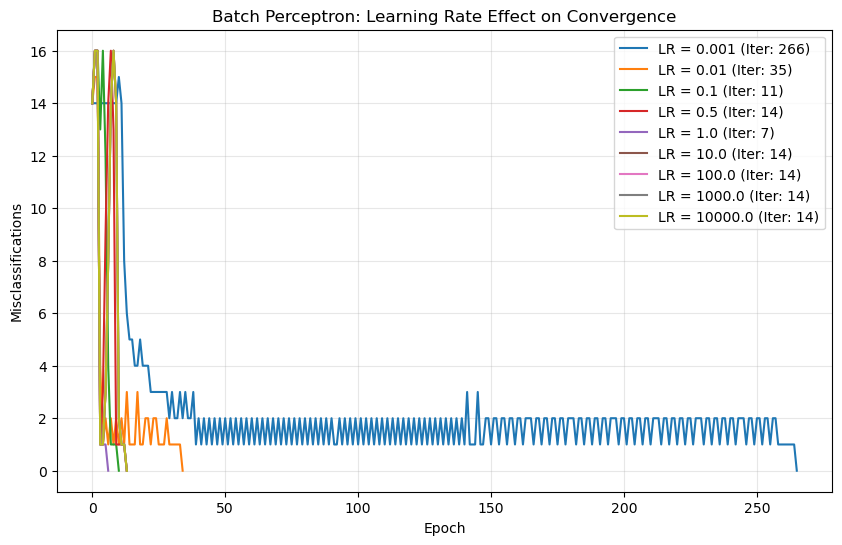

In [6]:
learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0, 10.0, 100.0, 1000.0, 10000.0]
batch_results = {}

for lr in learning_rates:
    perceptron = BatchPerceptron(lr=lr, epochs=1000, random_state=42)
    perceptron.fit(X_train, Y_train)
    batch_results[lr] = {
        'errors': perceptron.errors,
        'iterations': len(perceptron.errors),
        'converged': perceptron.errors[-1] == 0
    }
    
    Y_pred = perceptron.predict(X_test)
    accuracy = np.mean(Y_pred == Y_test.flatten())
    print(f"Batch LR {lr}: Iterations = {len(perceptron.errors)}, Converged = {perceptron.errors[-1] == 0}, Test Accuracy = {accuracy:.4f}")

plt.figure(figsize=(10, 6))
for lr, result in batch_results.items():
    plt.plot(result['errors'], label=f'LR = {lr} (Iter: {result["iterations"]})')
plt.xlabel('Epoch')
plt.ylabel('Misclassifications')
plt.title('Batch Perceptron: Learning Rate Effect on Convergence')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### For batch training, I believe that regardless of the learning rate, the results obtained on the test set are good. However, the number of iterations increases when the learning rate is too high, so I think there is oscillation in the iterations when the learning rate is too high. So I chose a starting value of 0.1, where the number of iterations increases as the learning rate decreases. I believe that a learning rate of 0.1 is relatively stable for batch training.

In [7]:
sequential_results = {}

for lr in learning_rates:
    perceptron = SequentialPerceptron(lr=lr, epochs=100, random_state=42)
    perceptron.fit(X_train, Y_train)
    
    sequential_results[lr] = {
        'iterations': len(perceptron.weights_history)
    }
    
    Y_pred = perceptron.predict(X_test)
    accuracy = np.mean(Y_pred == Y_test.flatten())
    print(f"Sequential LR {lr}: Iterations = {len(perceptron.weights_history)}, Test Accuracy = {accuracy:.4f}")

Sequential LR 0.001: Iterations = 355, Test Accuracy = 1.0000
Sequential LR 0.01: Iterations = 72, Test Accuracy = 1.0000
Sequential LR 0.1: Iterations = 19, Test Accuracy = 1.0000
Sequential LR 0.5: Iterations = 19, Test Accuracy = 0.9500
Sequential LR 1.0: Iterations = 23, Test Accuracy = 0.9500
Sequential LR 10.0: Iterations = 20, Test Accuracy = 1.0000
Sequential LR 100.0: Iterations = 23, Test Accuracy = 0.9500
Sequential LR 1000.0: Iterations = 23, Test Accuracy = 0.9500
Sequential LR 10000.0: Iterations = 23, Test Accuracy = 0.9500


#### For sequential training, the impact of learning rate is the same. Excessive learning rate can lead to an increase in the number of iterations until it becomes fixed, and I also believe that oscillations occur during the training process. And too high a learning rate can lead to poor test results, so I chose a learning rate of 0.1. A learning rate smaller than 0.1 will significantly increase the number of iterations, and the test results obtained with a learning rate of 0.1 are also good. A larger learning rate may result in poor test results or more training iterations.